# Laptop Dataset Analysis

## 1. Introduction

The laptop dataset contains information about laptop manufacturers, specifications, operating systems, physical characteristics, and pricing. The objective of this project is to analyze the dataset to understand laptop characteristics, performance-related specifications, and factors associated with laptop pricing.

The analysis focuses on data cleaning, exploratory data analysis, visualization, feature engineering, and interpretation of the relationships between laptop specifications and price.

# 2. Aim

The aim of this project is to perform a comprehensive exploratory analysis of the laptop dataset to understand laptop specifications, pricing patterns, relationships between different features, and the key characteristics associated with laptop prices.

# 3. Business Problem

Laptop manufacturers, retailers, and consumers need to understand how different laptop specifications are associated with pricing.

This project investigates questions such as:

- Which laptop specifications are most strongly associated with price?
- How does RAM affect laptop pricing?
- Does storage capacity influence price?
- How are CPU and GPU characteristics related to price?
- Do screen specifications have an association with laptop price?
- Which brands and operating systems are associated with different price levels?
- What patterns can be identified from multiple laptop specifications together?

# 4. Project Workflow

1. Import libraries and load the dataset
2. Understand the dataset structure
3. Clean and preprocess the data
4. Handle missing and inconsistent values
5. Detect and analyze outliers
6. Perform feature engineering
7. Prepare and filter data for analysis
8. Perform statistical analysis
9. Conduct univariate analysis
10. Conduct bivariate analysis
11. Conduct multivariate analysis
12. Interpret the findings
13. Provide recommendations
14. Conclude the analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)

In [10]:
df = pd.read_csv('../data/laptop.csv')

In [13]:
df_clean = df.copy()

In [14]:
df_clean

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080
...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1298.0,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.6400
1299,1299.0,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.7200
1300,1300.0,Lenovo,Notebook,65.4,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.1200
1301,1301.0,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.9200


In [15]:
df_clean.shape

(1303, 12)

In [16]:
df_clean.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


# 6. Data Understanding

The laptop dataset contains information about laptop manufacturers, laptop types, screen specifications, processor and memory details, graphics processors, operating systems, weight, and price.

The raw dataset contains 1,303 records and 12 columns, including an index column (`Unnamed: 0`). The index column will be removed during the data-cleaning stage because it does not represent a meaningful laptop characteristic.

In [17]:
df_clean.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='str')

In [19]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   str    
 2   TypeName          1253 non-null   str    
 3   Inches            1220 non-null   str    
 4   ScreenResolution  1273 non-null   str    
 5   Cpu               1273 non-null   str    
 6   Ram               1259 non-null   str    
 7   Memory            1273 non-null   str    
 8   Gpu               1273 non-null   str    
 9   OpSys             1273 non-null   str    
 10  Weight            1259 non-null   str    
 11  Price             1273 non-null   float64
dtypes: float64(2), str(10)
memory usage: 122.3 KB


In [22]:
df_clean.isnull().sum()

Unnamed: 0          30
Company             30
TypeName            50
Inches              83
ScreenResolution    30
Cpu                 30
Ram                 44
Memory              30
Gpu                 30
OpSys               30
Weight              44
Price               30
dtype: int64

In [23]:
df_clean.duplicated().sum()

np.int64(29)

# 7. Data Cleaning and Preprocessing

In [48]:
df_clean = df_clean.drop(columns=['Unnamed: 0'])

In [49]:
df_clean.shape

(1303, 11)

In [50]:
df_clean.columns

Index(['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram',
       'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='str')

In [51]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1273 non-null   str    
 1   TypeName          1253 non-null   str    
 2   Inches            1219 non-null   float64
 3   ScreenResolution  1273 non-null   str    
 4   Cpu               1273 non-null   str    
 5   Ram               0 non-null      float64
 6   Memory            1273 non-null   str    
 7   Gpu               1273 non-null   str    
 8   OpSys             1273 non-null   str    
 9   Weight            1303 non-null   float64
 10  Price             1273 non-null   float64
dtypes: float64(4), str(7)
memory usage: 112.1 KB


In [52]:
df_clean.isnull().sum()

Company               30
TypeName              50
Inches                84
ScreenResolution      30
Cpu                   30
Ram                 1303
Memory                30
Gpu                   30
OpSys                 30
Weight                 0
Price                 30
dtype: int64

In [53]:
df_clean.duplicated().sum()

np.int64(58)

## Initial Data Quality Assessment

The dataset initially contained 1,303 records and 11 variables. Missing values were identified in several columns, including Company, TypeName, Inches, ScreenResolution, Cpu, Ram, Memory, Gpu, OpSys, and Price. The dataset also contained 58 duplicate rows.

The Ram column requires additional investigation because all 1,303 entries were identified as missing in the loaded dataset.

In [54]:
df_clean['Ram'].head(20)

0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
10   NaN
11   NaN
12   NaN
13   NaN
14   NaN
15   NaN
16   NaN
17   NaN
18   NaN
19   NaN
Name: Ram, dtype: float64

In [55]:
df_clean['Ram'].unique()

array([nan])

In [56]:
df_clean['Ram'].value_counts(dropna=False)

Ram
NaN    1303
Name: count, dtype: int64

In [57]:
df.columns.tolist()

['Unnamed: 0',
 'Company',
 'TypeName',
 'Inches',
 'ScreenResolution',
 'Cpu',
 'Ram',
 'Memory',
 'Gpu',
 'OpSys',
 'Weight',
 'Price']

In [ ]:
import csv

with open('../data/laptop.csv', 'r', encoding='utf-8') as f:reader = csv.reader(f)
header = next(reader)
first_row = next(reader)

print(header)
print(first_row)

['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price']
['0', 'Apple', 'Ultrabook', '13.3', 'IPS Panel Retina Display 2560x1600', 'Intel Core i5 2.3GHz', '8GB', '128GB SSD', 'Intel Iris Plus Graphics 640', 'macOS', '1.37kg', '71378.6832']


In [ ]:
df = pd.read_csv(
'../data/laptop.csv',
engine='python'
)

In [60]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [61]:
df['Ram'].head()

0     8GB
1     8GB
2     8GB
3    16GB
4     8GB
Name: Ram, dtype: str

In [62]:
df['Ram'].value_counts().head(10)

Ram
8GB     594
4GB     362
16GB    194
6GB      39
12GB     24
2GB      22
32GB     17
64GB      3
24GB      3
1GB       1
Name: count, dtype: int64

In [63]:
df.shape

(1303, 12)

In [64]:
df_clean = df.copy()

In [65]:
df_clean = df_clean.drop(columns=['Unnamed: 0'])

In [66]:
df_clean.shape

(1303, 11)

In [67]:
df_clean.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [24]:
df_clean['Weight'].head()

0    1.37kg
1    1.34kg
2    1.86kg
3    1.83kg
4    1.37kg
Name: Weight, dtype: str

In [ ]:
df_clean['Weight'] = pd.to_numeric(
df_clean['Weight'].astype(str).str.replace('kg', '', regex=False).str.strip(),
errors='coerce'
)

In [26]:
df_clean['Weight'].dtype

dtype('float64')

In [27]:
df_clean['Weight'].isnull().sum()

np.int64(46)

In [ ]:
df_clean['Weight'] = df_clean['Weight'].fillna(
df_clean['Weight'].median()
)

In [29]:
df_clean['Weight'].isnull().sum()

np.int64(0)

In [30]:
df_clean['Inches'].unique()

<StringArray>
[ '13.3',  '15.6',  '15.4',    '14',    '12',     nan,  '17.3',  '13.5',
  '12.5',    '13',  '18.4',  '13.9',  '11.6',  '25.6',  '35.6',  '12.3',
  '27.3',    '24',  '33.5',     '?',  '31.6',    '17',    '15',  '14.1',
  '11.3',  '88.1',  '21.8',  '10.1',  '75.7',   '8.4',   '2.1', '111.8',
  '89.2',  '65.4']
Length: 34, dtype: str

In [ ]:
df_clean['Inches'] = pd.to_numeric(
df_clean['Inches'],
errors='coerce'
)

In [32]:
df_clean['Inches'].describe()

count    1219.000000
mean       15.412059
std         5.060713
min         2.100000
25%        14.000000
50%        15.600000
75%        15.600000
max       111.800000
Name: Inches, dtype: float64

In [33]:
df_clean['Inches'].sort_values().unique()

array([  2.1,   8.4,  10.1,  11.3,  11.6,  12. ,  12.3,  12.5,  13. ,
        13.3,  13.5,  13.9,  14. ,  14.1,  15. ,  15.4,  15.6,  17. ,
        17.3,  18.4,  21.8,  24. ,  25.6,  27.3,  31.6,  33.5,  35.6,
        65.4,  75.7,  88.1,  89.2, 111.8,   nan])

In [ ]:
df_clean['Price'] = pd.to_numeric(
df_clean['Price'],
errors='coerce'
)

In [35]:
df_clean['Price'].isnull().sum()

np.int64(30)

In [36]:
df_clean['Ram'].head()

0     8GB
1     8GB
2     8GB
3    16GB
4     8GB
Name: Ram, dtype: str

In [ ]:
df_clean['Ram'] = pd.to_numeric(
df_clean['Ram'],
errors='coerce'
)

In [38]:
df_clean.isnull().sum()

Unnamed: 0            30
Company               30
TypeName              50
Inches                84
ScreenResolution      30
Cpu                   30
Ram                 1303
Memory                30
Gpu                   30
OpSys                 30
Weight                 0
Price                 30
dtype: int64

In [39]:
df_clean.duplicated().sum()

np.int64(29)

In [70]:
print(df_clean['Ram'].notna().sum())
print(df_clean['Ram'].isna().sum())

1259
44


In [71]:
df_clean.isnull().sum()

Company             30
TypeName            50
Inches              83
ScreenResolution    30
Cpu                 30
Ram                 44
Memory              30
Gpu                 30
OpSys               30
Weight              44
Price               30
dtype: int64

In [76]:
df_clean['Ram'] = df_clean['Ram'].str.replace('GB', '', regex=False)
df_clean['Ram'] = pd.to_numeric(df_clean['Ram'], errors='coerce')

In [77]:
df_clean['Ram'].dtype

dtype('float64')

In [78]:
df_clean['Weight'] = df_clean['Weight'].str.replace('kg', '', regex=False)
df_clean['Weight'] = pd.to_numeric(df_clean['Weight'], errors='coerce')

In [79]:
df_clean['Weight'].dtype

dtype('float64')

In [80]:
df_clean['Inches'] = pd.to_numeric(df_clean['Inches'], errors='coerce')

In [81]:
df_clean['Inches'].dtype

dtype('float64')

In [82]:
df_clean.isnull().sum()

Company             30
TypeName            50
Inches              84
ScreenResolution    30
Cpu                 30
Ram                 44
Memory              30
Gpu                 30
OpSys               30
Weight              46
Price               30
dtype: int64

In [83]:
df_clean.dtypes

Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                 float64
Memory                  str
Gpu                     str
OpSys                   str
Weight              float64
Price               float64
dtype: object

In [84]:
df_clean['Inches'] = df_clean['Inches'].fillna(df_clean['Inches'].median())
df_clean['Ram'] = df_clean['Ram'].fillna(df_clean['Ram'].median())
df_clean['Weight'] = df_clean['Weight'].fillna(df_clean['Weight'].median())

In [ ]:
categorical_cols = [
'Company',
'TypeName',
'ScreenResolution',
'Cpu',
'Memory',
'Gpu',
'OpSys'
]

df_clean[categorical_cols] = df_clean[categorical_cols].fillna('Unknown')

In [87]:
df_clean = df_clean.dropna(subset=['Price'])

In [88]:
df_clean.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [89]:
df_clean.shape

(1273, 11)

In [90]:
df_clean.duplicated().sum()

np.int64(28)

In [91]:
df_clean = df_clean.drop_duplicates()

In [92]:
df_clean.shape

(1245, 11)

In [93]:
df_clean.duplicated().sum()

np.int64(0)

In [94]:
df_clean.dtypes

Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                 float64
Memory                  str
Gpu                     str
OpSys                   str
Weight              float64
Price               float64
dtype: object

In [95]:
df_clean.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [96]:
df_clean.describe()

,Inches,Ram,Weight,Price
count,1245.000000,1245.000000,1245.000000,1245.000000
mean,15.433655,8.537349,2.150554,60567.344825
std,5.003354,5.579123,1.401069,37434.736222
min,2.100000,1.000000,0.000080,9270.720000
25%,14.000000,4.000000,1.500000,32639.860800
50%,15.600000,8.000000,2.040000,52693.920000
75%,15.600000,8.000000,2.330000,79813.440000
max,111.800000,64.000000,29.000000,324954.720000


In [98]:
print("Inches:", sorted(df_clean['Inches'].unique()))
print("Ram:", sorted(df_clean['Ram'].unique()))

Inches: [np.float64(2.1), np.float64(8.4), np.float64(10.1), np.float64(11.3), np.float64(11.6), np.float64(12.0), np.float64(12.3), np.float64(12.5), np.float64(13.0), np.float64(13.3), np.float64(13.5), np.float64(13.9), np.float64(14.0), np.float64(14.1), np.float64(15.0), np.float64(15.4), np.float64(15.6), np.float64(17.0), np.float64(17.3), np.float64(18.4), np.float64(21.8), np.float64(24.0), np.float64(25.6), np.float64(27.3), np.float64(31.6), np.float64(33.5), np.float64(35.6), np.float64(65.4), np.float64(75.7), np.float64(88.1), np.float64(89.2), np.float64(111.8)]
Ram: [np.float64(1.0), np.float64(2.0), np.float64(4.0), np.float64(6.0), np.float64(8.0), np.float64(12.0), np.float64(16.0), np.float64(24.0), np.float64(32.0), np.float64(64.0)]


In [99]:
print(sorted(df_clean['Weight'].unique()))

[np.float64(8e-05), np.float64(0.0002), np.float64(0.69), np.float64(0.81), np.float64(0.91), np.float64(0.92), np.float64(0.97), np.float64(0.98), np.float64(0.99), np.float64(1.05), np.float64(1.08), np.float64(1.09), np.float64(1.1), np.float64(1.11), np.float64(1.12), np.float64(1.13), np.float64(1.14), np.float64(1.15), np.float64(1.16), np.float64(1.17), np.float64(1.18), np.float64(1.19), np.float64(1.2), np.float64(1.21), np.float64(1.22), np.float64(1.23), np.float64(1.24), np.float64(1.25), np.float64(1.252), np.float64(1.26), np.float64(1.27), np.float64(1.28), np.float64(1.29), np.float64(1.3), np.float64(1.31), np.float64(1.32), np.float64(1.34), np.float64(1.35), np.float64(1.36), np.float64(1.37), np.float64(1.38), np.float64(1.39), np.float64(1.4), np.float64(1.41), np.float64(1.42), np.float64(1.43), np.float64(1.44), np.float64(1.45), np.float64(1.47), np.float64(1.48), np.float64(1.49), np.float64(1.5), np.float64(1.54), np.float64(1.55), np.float64(1.56), np.float64

In [ ]:
df_clean[df_clean['Inches'] > 18.4][
['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Price']
]

,Company,TypeName,Inches,ScreenResolution,Price
402,Lenovo,Notebook,25.6,IPS Panel Full HD 1920x1080,60978.9600
408,Lenovo,Notebook,35.6,Full HD 1920x1080,21791.5200
423,Asus,Notebook,35.6,Full HD 1920x1080,31808.1600
424,Dell,Gaming,27.3,IPS Panel 2560x1440,149130.7200
438,Lenovo,Ultrabook,24.0,2560x1440,126912.9600
458,Microsoft,Ultrabook,33.5,Touchscreen 2256x1504,95850.7200
525,Lenovo,Notebook,24.0,Full HD 1920x1080,71395.2000
592,Dell,2 in 1 Convertible,31.6,Touchscreen 1366x768,32127.8400
673,Lenovo,Notebook,35.6,1366x768,18594.7200
1007,HP,Ultrabook,88.1,Full HD 1920x1080,77202.7200


In [ ]:
df_clean[df_clean['Inches'] < 10][
['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Price']
]

,Company,TypeName,Inches,ScreenResolution,Price
1135,Lenovo,Notebook,8.4,Full HD 1920x1080,58554.7200
1158,Lenovo,Notebook,2.1,Full HD 1920x1080,42010.7472


In [ ]:
df_clean[df_clean['Weight'] > 5][
['Company', 'TypeName', 'Weight', 'Price']
]

,Company,TypeName,Weight,Price
133,Acer,Notebook,7.20,30476.1600
173,Toshiba,Notebook,5.40,26053.9200
240,Lenovo,Notebook,7.20,31381.9200
302,Lenovo,Notebook,5.80,34578.7200
326,Acer,Notebook,8.23,29250.7200
408,Lenovo,Notebook,22.10,21791.5200
505,Lenovo,Notebook,9.00,50562.7200
537,HP,Notebook,10.00,21258.1872
578,MSI,Gaming,14.00,145401.1200
587,Lenovo,Ultrabook,8.40,89137.4400


In [ ]:
df_clean[df_clean['Weight'] < 0.5][
['Company', 'TypeName', 'Weight', 'Price']
]

,Company,TypeName,Weight,Price
349,Dell,Ultrabook,0.00020,35324.64
397,Lenovo,Notebook,0.00008,49976.64


In [ ]:
df_clean.loc[
(df_clean['Inches'] < 10) | (df_clean['Inches'] > 18.4),
'Inches'
] = np.nan

In [105]:
df_clean['Inches'] = df_clean['Inches'].fillna(df_clean['Inches'].median())

In [ ]:
df_clean.loc[
(df_clean['Weight'] < 0.5) | (df_clean['Weight'] > 5),
'Weight'
] = np.nan

In [107]:
df_clean['Weight'] = df_clean['Weight'].fillna(df_clean['Weight'].median())

In [108]:
df_clean[['Inches', 'Ram', 'Weight', 'Price']].describe()

,Inches,Ram,Weight,Price
count,1245.000000,1245.000000,1245.000000,1245.000000
mean,15.056064,8.537349,2.046948,60567.344825
std,1.377701,5.579123,0.666826,37434.736222
min,10.100000,1.000000,0.690000,9270.720000
25%,14.000000,4.000000,1.540000,32639.860800
50%,15.600000,8.000000,2.040000,52693.920000
75%,15.600000,8.000000,2.310000,79813.440000
max,18.400000,64.000000,4.700000,324954.720000


In [109]:
df_clean.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [110]:
print(df_clean['Company'].value_counts())

Company
Lenovo       283
Dell         281
HP           260
Asus         149
Acer         101
MSI           53
Toshiba       47
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
LG             3
Huawei         2
Fujitsu        2
Name: count, dtype: int64


In [111]:
print(df_clean['TypeName'].value_counts())

TypeName
Notebook              673
Gaming                202
Ultrabook             189
2 in 1 Convertible    110
Workstation            29
Netbook                22
Unknown                20
Name: count, dtype: int64


In [112]:
print(df_clean['OpSys'].value_counts())

OpSys
Windows 10      1023
No OS             63
Linux             57
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            1
Name: count, dtype: int64


In [113]:
print(df_clean['Gpu'].value_counts().head(20))

Gpu
Intel HD Graphics 620         269
Intel HD Graphics 520         177
Intel UHD Graphics 620         66
Nvidia GeForce GTX 1050        64
Nvidia GeForce GTX 1060        48
Nvidia GeForce 940MX           42
AMD Radeon 530                 39
Intel HD Graphics 500          39
Intel HD Graphics 400          30
Nvidia GeForce GTX 1070        29
Nvidia GeForce GTX 1050 Ti     27
Intel HD Graphics              23
AMD Radeon R5 M430             20
Nvidia GeForce 930MX           20
AMD Radeon 520                 16
Nvidia GeForce MX150           15
Intel HD Graphics 615          14
AMD Radeon R7 M445             14
Intel HD Graphics 515          13
Nvidia GeForce 920MX           12
Name: count, dtype: int64


# 8. Feature Engineering
CPU_Family
GPU_Brand
SSD_GB
HDD_GB
Flash_GB
Hybrid_GB
Total_Storage_GB
Screen_Width
Screen_Height
Resolution_Pixels
Touchscreen
IPS_Panel
Retina_Display
CPU_Speed_GHz

In [114]:
df_clean['CPU_Speed_GHz'] = df_clean['Cpu'].str.extract(r'(\d+(?:\.\d+)?)GHz')[0]
df_clean['CPU_Speed_GHz'] = pd.to_numeric(df_clean['CPU_Speed_GHz'], errors='coerce')

In [115]:
df_clean['CPU_Family'] = df_clean['Cpu'].str.extract(
    r'(Intel Core i[3579]|AMD Ryzen [3579]|Intel Pentium|Intel Celeron|Intel Atom|AMD A[468]|AMD FX|AMD E-Series)',
    expand=False
)

In [116]:
df_clean['GPU_Brand'] = df_clean['Gpu'].str.extract(
    r'(Intel|Nvidia|AMD)',
    expand=False
)

In [117]:
print(df_clean['GPU_Brand'].value_counts())

GPU_Brand
Intel     685
Nvidia    389
AMD       170
Name: count, dtype: int64


In [118]:
df_clean[['Cpu', 'CPU_Family', 'CPU_Speed_GHz']].head(10)

,Cpu,CPU_Family,CPU_Speed_GHz
0,Intel Core i5 2.3GHz,Intel Core i5,2.3
1,Intel Core i5 1.8GHz,Intel Core i5,1.8
2,Intel Core i5 7200U 2.5GHz,Intel Core i5,2.5
3,Intel Core i7 2.7GHz,Intel Core i7,2.7
4,Intel Core i5 3.1GHz,Intel Core i5,3.1
5,AMD A9-Series 9420 3GHz,NaN,3.0
6,Intel Core i7 2.2GHz,Intel Core i7,2.2
7,Intel Core i5 1.8GHz,Intel Core i5,1.8
8,Intel Core i7 8550U 1.8GHz,Intel Core i7,1.8
9,Intel Core i5 8250U 1.6GHz,Intel Core i5,1.6


In [119]:
df_clean[['Gpu', 'GPU_Brand']].head(10)

,Gpu,GPU_Brand
0,Intel Iris Plus Graphics 640,Intel
1,Intel HD Graphics 6000,Intel
2,Intel HD Graphics 620,Intel
3,AMD Radeon Pro 455,AMD
4,Intel Iris Plus Graphics 650,Intel
5,AMD Radeon R5,AMD
6,Intel Iris Pro Graphics,Intel
7,Intel HD Graphics 6000,Intel
8,Nvidia GeForce MX150,Nvidia
9,Intel UHD Graphics 620,Intel


In [120]:
df_clean['CPU_Family'].isnull().sum()

np.int64(55)

In [121]:
df_clean[df_clean['CPU_Family'].isnull()]['Cpu'].value_counts()

Cpu
AMD A9-Series 9420 3GHz            11
Intel Core M 6Y75 1.2GHz            5
AMD A12-Series 9720P 3.6GHz         5
AMD Ryzen 1700 3GHz                 3
Intel Xeon E3-1505M V6 3GHz         2
AMD A10-Series A10-9620P 2.5GHz     2
AMD A10-Series 9600P 2.4GHz         2
AMD A12-Series 9720P 2.7GHz         2
AMD A10-Series 9620P 2.5GHz         2
AMD A9-Series A9-9420 3GHz          2
Intel Core M 1.2GHz                 2
Intel Core M 1.1GHz                 2
Intel Core M m3 1.2GHz              1
AMD Ryzen 1600 3.2GHz               1
Intel Core M m3-7Y30 2.2GHz         1
Intel Core M 7Y30 1.0GHz            1
Intel Xeon E3-1535M v6 3.1GHz       1
Intel Core M M3-6Y30 0.9GHz         1
AMD A9-Series 9420 2.9GHz           1
Intel Xeon E3-1535M v5 2.9GHz       1
AMD A12-Series 9700P 2.5GHz         1
Intel Core M m7-6Y75 1.2GHz         1
Intel Core M M7-6Y75 1.2GHz         1
Intel Core M 6Y54 1.1GHz            1
Samsung Cortex A72&A53 2.0GHz       1
Intel Core M 6Y30 0.9GHz            1
AMD A9-S

In [122]:
df_clean['CPU_Speed_GHz'].isnull().sum()

np.int64(0)

In [123]:
df_clean['GPU_Brand'].value_counts(dropna=False)

GPU_Brand
Intel     685
Nvidia    389
AMD       170
NaN         1
Name: count, dtype: int64

In [ ]:
df_clean['CPU_Family'] = df_clean['Cpu'].str.extract(
r'(Intel Core i[3579]|Intel Core M|Intel Xeon|'
r'AMD Ryzen|AMD A(?:4|6|8|9|10|12)-Series|'
r'AMD FX|AMD E-Series|Intel Pentium|Intel Celeron|'
r'Intel Atom|Samsung Cortex)',
expand=False
)

In [129]:
df_clean['CPU_Family'].value_counts(dropna=False)

CPU_Family
Intel Core i7     503
Intel Core i5     410
Intel Core i3     132
Intel Celeron      77
Intel Pentium      30
Intel Core M       17
AMD A9-Series      15
Intel Atom         11
AMD A6-Series      11
AMD E-Series        9
AMD A12-Series      8
AMD A10-Series      6
AMD Ryzen           4
Intel Xeon          4
AMD A8-Series       4
AMD FX              2
AMD A4-Series       1
Samsung Cortex      1
Name: count, dtype: int64

In [130]:
df_clean['CPU_Family'].isnull().sum()

np.int64(0)

In [ ]:
df_clean['GPU_Brand'] = df_clean['Gpu'].str.extract(
r'(Intel|Nvidia|AMD|ARM)',
expand=False
)

In [133]:
print("CPU missing:", df_clean['CPU_Family'].isnull().sum())
print("GPU missing:", df_clean['GPU_Brand'].isnull().sum())

CPU missing: 0
GPU missing: 0


In [132]:
df_clean['GPU_Brand'].value_counts(dropna=False)

GPU_Brand
Intel     685
Nvidia    389
AMD       170
ARM         1
Name: count, dtype: int64

In [135]:
df_clean['Memory'].value_counts()

Memory
256GB SSD                        401
1TB HDD                          209
500GB HDD                        121
512GB SSD                        112
128GB SSD +  1TB HDD              92
128GB SSD                         72
256GB SSD +  1TB HDD              71
32GB Flash Storage                35
2TB HDD                           16
512GB SSD +  1TB HDD              14
64GB Flash Storage                13
1TB SSD                           13
256GB SSD +  2TB HDD              10
256GB Flash Storage                8
1.0TB Hybrid                       7
16GB Flash Storage                 7
32GB SSD                           6
128GB Flash Storage                4
180GB SSD                          4
16GB SSD                           3
512GB SSD +  2TB HDD               3
256GB SSD +  256GB SSD             2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
1TB SSD +  1TB HDD                 2
512GB Flash Storage                2
64GB SSD                       

In [136]:
memory = df_clean['Memory'].fillna('')

In [ ]:
df_clean['SSD_GB'] = (
memory.str.extract(r'(\d+(?:\.\d+)?)\s*GB\s*SSD', expand=False)
.astype(float)
.fillna(0)
)

In [ ]:
hdd = memory.str.extract(
r'(\d+(?:\.\d+)?)\s*(GB|TB)\s*HDD',
expand=True
)

df_clean['HDD_GB'] = hdd[0].astype(float).fillna(0)

df_clean.loc[hdd[1] == 'TB', 'HDD_GB'] *= 1000

In [ ]:
flash = memory.str.extract(
r'(\d+(?:\.\d+)?)\s*(GB|TB)\s*Flash Storage',
expand=True
)

df_clean['Flash_GB'] = flash[0].astype(float).fillna(0)

df_clean.loc[flash[1] == 'TB', 'Flash_GB'] *= 1000

In [ ]:
hybrid = memory.str.extract(
r'(\d+(?:\.\d+)?)\s*(GB|TB)\s*Hybrid',
expand=True
)

df_clean['Hybrid_GB'] = hybrid[0].astype(float).fillna(0)

df_clean.loc[hybrid[1] == 'TB', 'Hybrid_GB'] *= 1000

In [ ]:
df_clean['Total_Storage_GB'] = (
df_clean['SSD_GB'] +
df_clean['HDD_GB'] +
df_clean['Flash_GB'] +
df_clean['Hybrid_GB']
)

In [ ]:
df_clean[
['Memory', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB', 'Total_Storage_GB']
].head(20)

,Memory,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB,Total_Storage_GB
0,128GB SSD,128.0,0.0,0.0,0.0,128.0
1,128GB Flash Storage,0.0,0.0,128.0,0.0,128.0
2,256GB SSD,256.0,0.0,0.0,0.0,256.0
3,512GB SSD,512.0,0.0,0.0,0.0,512.0
4,256GB SSD,256.0,0.0,0.0,0.0,256.0
5,500GB HDD,0.0,500.0,0.0,0.0,500.0
6,256GB Flash Storage,0.0,0.0,256.0,0.0,256.0
7,256GB Flash Storage,0.0,0.0,256.0,0.0,256.0
8,512GB SSD,512.0,0.0,0.0,0.0,512.0
9,256GB SSD,256.0,0.0,0.0,0.0,256.0


In [ ]:
df_clean[
['SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB', 'Total_Storage_GB']
].describe()

,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB,Total_Storage_GB
count,1245.000000,1245.000000,1245.000000,1245.000000,1245.000000
mean,172.510843,413.381526,4.587952,7.636948,598.117269
std,161.349482,517.395524,30.836171,85.929062,469.404770
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,256.000000
50%,180.000000,0.000000,0.000000,0.000000,500.000000
75%,256.000000,1000.000000,0.000000,0.000000,1000.000000
max,512.000000,2000.000000,512.000000,1000.000000,2512.000000


In [ ]:
resolution = df_clean['ScreenResolution'].str.extract(
r'(\d+)\s*x\s*(\d+)',
expand=True
)

df_clean['Screen_Width'] = pd.to_numeric(resolution[0], errors='coerce')
df_clean['Screen_Height'] = pd.to_numeric(resolution[1], errors='coerce')

In [ ]:
df_clean['Resolution_Pixels'] = (
df_clean['Screen_Width'] * df_clean['Screen_Height']
)

In [ ]:
df_clean['Touchscreen'] = df_clean['ScreenResolution'].str.contains(
'Touchscreen',
case=False,
na=False
)

In [ ]:
df_clean['IPS_Panel'] = df_clean['ScreenResolution'].str.contains(
'IPS Panel',
case=False,
na=False
)

In [ ]:
df_clean['Retina_Display'] = df_clean['ScreenResolution'].str.contains(
'Retina Display',
case=False,
na=False
)

In [ ]:
df_clean[
['ScreenResolution',
'Screen_Width',
'Screen_Height',
'Resolution_Pixels',
'Touchscreen',
'IPS_Panel',
'Retina_Display']
].head(20)

,ScreenResolution,Screen_Width,Screen_Height,Resolution_Pixels,Touchscreen,IPS_Panel,Retina_Display
0,IPS Panel Retina Display 2560x1600,2560,1600,4096000,False,True,True
1,1440x900,1440,900,1296000,False,False,False
2,Full HD 1920x1080,1920,1080,2073600,False,False,False
3,IPS Panel Retina Display 2880x1800,2880,1800,5184000,False,True,True
4,IPS Panel Retina Display 2560x1600,2560,1600,4096000,False,True,True
5,1366x768,1366,768,1049088,False,False,False
6,IPS Panel Retina Display 2880x1800,2880,1800,5184000,False,True,True
7,1440x900,1440,900,1296000,False,False,False
8,Full HD 1920x1080,1920,1080,2073600,False,False,False
9,IPS Panel Full HD 1920x1080,1920,1080,2073600,False,True,False


In [151]:
print(df_clean['Touchscreen'].value_counts())
print(df_clean['IPS_Panel'].value_counts())
print(df_clean['Retina_Display'].value_counts())

Touchscreen
False    1064
True      181
Name: count, dtype: int64
IPS_Panel
False    894
True     351
Name: count, dtype: int64
Retina_Display
False    1228
True       17
Name: count, dtype: int64


In [155]:
df_clean.isnull().sum()

Company              0
TypeName             0
Inches               0
ScreenResolution     0
Cpu                  0
Ram                  0
Memory               0
Gpu                  0
OpSys                0
Weight               0
Price                0
CPU_Speed_GHz        0
CPU_Family           0
GPU_Brand            0
SSD_GB               0
HDD_GB               0
Flash_GB             0
Hybrid_GB            0
Total_Storage_GB     0
Screen_Width         0
Screen_Height        0
Resolution_Pixels    0
Touchscreen          0
IPS_Panel            0
Retina_Display       0
dtype: int64

In [153]:
df_clean.shape

(1245, 25)

In [154]:
df_clean.dtypes

Company                  str
TypeName                 str
Inches               float64
ScreenResolution         str
Cpu                      str
Ram                  float64
Memory                   str
Gpu                      str
OpSys                    str
Weight               float64
Price                float64
CPU_Speed_GHz        float64
CPU_Family               str
GPU_Brand                str
SSD_GB               float64
HDD_GB               float64
Flash_GB             float64
Hybrid_GB            float64
Total_Storage_GB     float64
Screen_Width           int64
Screen_Height          int64
Resolution_Pixels      int64
Touchscreen             bool
IPS_Panel               bool
Retina_Display          bool
dtype: object

# 9. Prepare Data For Analysis

In [156]:
Q1 = df_clean['Price'].quantile(0.25)
Q3 = df_clean['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 32639.8608
Q3: 79813.44
IQR: 47173.57920000001
Lower Bound: -38120.508000000016
Upper Bound: 150573.8088


In [ ]:
price_outliers = df_clean[
(df_clean['Price'] < lower_bound) |
(df_clean['Price'] > upper_bound)
]

print("Number of Price outliers:", len(price_outliers))

Number of Price outliers: 28


In [ ]:
price_outliers[['Company', 'TypeName', 'Ram', 'CPU_Family',
'GPU_Brand', 'Total_Storage_GB', 'Price']].sort_values(
'Price', ascending=False
).head(20)

,Company,TypeName,Ram,CPU_Family,GPU_Brand,Total_Storage_GB,Price
196,Razer,Gaming,32.0,Intel Core i7,Nvidia,0.0,324954.7200
830,Razer,Gaming,32.0,Intel Core i7,Nvidia,512.0,292986.7200
610,Lenovo,Notebook,32.0,Intel Xeon,Nvidia,0.0,261018.7200
749,HP,Workstation,16.0,Intel Xeon,Nvidia,256.0,233845.9200
1066,Asus,Gaming,64.0,Intel Core i7,Nvidia,0.0,211788.0000
1136,HP,Workstation,8.0,Intel Core i7,Nvidia,256.0,210424.0320
238,Asus,Gaming,32.0,Intel Core i7,Nvidia,1512.0,207259.2000
723,Dell,Gaming,32.0,Intel Core i7,Nvidia,1000.0,194972.8320
780,Dell,Gaming,32.0,Intel Core i7,Nvidia,1000.0,191211.2640
1231,Razer,Gaming,16.0,Intel Core i7,Nvidia,0.0,186426.7200


In [161]:
Q1 = df_clean['Weight'].quantile(0.25)
Q3 = df_clean['Weight'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1.54
Q3: 2.31
IQR: 0.77
Lower Bound: 0.385
Upper Bound: 3.465


In [ ]:
weight_outliers = df_clean[
(df_clean['Weight'] < lower_bound) |
(df_clean['Weight'] > upper_bound)
]

print("Number of Weight outliers:", len(weight_outliers))

Number of Weight outliers: 49


In [ ]:
weight_outliers[
['Company', 'TypeName', 'Inches', 'Weight', 'Ram', 'Price']
].sort_values('Weight', ascending=False)

,Company,TypeName,Inches,Weight,Ram,Price
238,Asus,Gaming,17.3,4.70,32.0,207259.2000
1116,Lenovo,Gaming,15.6,4.60,16.0,146519.4672
1081,Lenovo,Gaming,15.6,4.60,32.0,172627.2000
1048,Lenovo,Gaming,17.3,4.60,16.0,122010.6672
577,Lenovo,Gaming,17.3,4.60,32.0,141884.6400
585,MSI,Gaming,17.3,4.50,16.0,125154.7200
780,Dell,Gaming,17.3,4.42,32.0,191211.2640
841,Dell,Gaming,17.3,4.42,32.0,163723.5792
552,Dell,Gaming,17.3,4.42,16.0,143802.7200
530,Dell,Gaming,17.3,4.42,16.0,160520.3856


In [164]:
Q1 = df_clean['Ram'].quantile(0.25)
Q3 = df_clean['Ram'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 4.0
Q3: 8.0
IQR: 4.0
Lower Bound: -2.0
Upper Bound: 14.0


In [ ]:
ram_outliers = df_clean[
(df_clean['Ram'] < lower_bound) |
(df_clean['Ram'] > upper_bound)
]

print("Number of RAM outliers:", len(ram_outliers))

Number of RAM outliers: 215


In [ ]:
ram_outliers[
['Company', 'TypeName', 'Ram', 'CPU_Family',
'GPU_Brand', 'Total_Storage_GB', 'Price']
].sort_values('Ram', ascending=False)

,Company,TypeName,Ram,CPU_Family,GPU_Brand,Total_Storage_GB,Price
1066,Asus,Gaming,64.0,Intel Core i7,Nvidia,0.0,211788.0000
720,Lenovo,Ultrabook,64.0,Intel Core i7,Intel,512.0,89864.1792
71,Dell,Ultrabook,64.0,Intel Core i7,AMD,256.0,50882.4000
491,Toshiba,Ultrabook,32.0,Intel Core i7,Intel,512.0,149130.7200
577,Lenovo,Gaming,32.0,Intel Core i7,Nvidia,1256.0,141884.6400
...,...,...,...,...,...,...,...
486,Dell,Workstation,16.0,Intel Core i7,Nvidia,512.0,124568.6400
487,Dell,Notebook,16.0,Intel Core i7,Nvidia,512.0,101178.7200
488,Lenovo,Ultrabook,16.0,Intel Core i7,Intel,512.0,95797.4400
489,Asus,Ultrabook,16.0,Intel Core i7,Intel,512.0,103896.0000


In [167]:
Q1 = df_clean['Total_Storage_GB'].quantile(0.25)
Q3 = df_clean['Total_Storage_GB'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 256.0
Q3: 1000.0
IQR: 744.0
Lower Bound: -860.0
Upper Bound: 2116.0


In [ ]:
storage_outliers = df_clean[
(df_clean['Total_Storage_GB'] < lower_bound) |
(df_clean['Total_Storage_GB'] > upper_bound)
]

print("Number of Storage outliers:", len(storage_outliers))

Number of Storage outliers: 15


In [ ]:
storage_outliers[
['Company', 'TypeName', 'Memory',
'SSD_GB', 'HDD_GB', 'Flash_GB',
'Hybrid_GB', 'Total_Storage_GB', 'Price']
].sort_values('Total_Storage_GB', ascending=False)

,Company,TypeName,Memory,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB,Total_Storage_GB,Price
370,Asus,2 in 1 Convertible,512GB SSD + 2TB HDD,512.0,2000.0,0.0,0.0,2512.0,58554.7200
894,MSI,Gaming,512GB SSD + 2TB HDD,512.0,2000.0,0.0,0.0,2512.0,141138.7200
977,Asus,2 in 1 Convertible,512GB SSD + 2TB HDD,512.0,2000.0,0.0,0.0,2512.0,95850.7200
58,MSI,Gaming,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,130482.7200
60,Dell,Notebook,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,69210.7200
121,MSI,Gaming,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,119427.1200
128,Dell,Notebook,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,74378.8800
180,Dell,Notebook,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,55890.7200
345,Lenovo,Gaming,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,60153.1200
426,Dell,Notebook,256GB SSD + 2TB HDD,256.0,2000.0,0.0,0.0,2256.0,60867.0720


In [170]:
Q1 = df_clean['CPU_Speed_GHz'].quantile(0.25)
Q3 = df_clean['CPU_Speed_GHz'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2.0
Q3: 2.7
IQR: 0.7000000000000002
Lower Bound: 0.9499999999999997
Upper Bound: 3.7500000000000004


In [ ]:
cpu_outliers = df_clean[
(df_clean['CPU_Speed_GHz'] < lower_bound) |
(df_clean['CPU_Speed_GHz'] > upper_bound)
]

print("Number of CPU Speed outliers:", len(cpu_outliers))

Number of CPU Speed outliers: 2


In [ ]:
cpu_outliers[
['Company', 'TypeName', 'Cpu',
'CPU_Family', 'CPU_Speed_GHz', 'Ram', 'Price']
].sort_values('CPU_Speed_GHz', ascending=False)

,Company,TypeName,Cpu,CPU_Family,CPU_Speed_GHz,Ram,Price
697,Asus,2 in 1 Convertible,Intel Core M M3-6Y30 0.9GHz,Intel Core M,0.9,4.0,35644.32
1261,Asus,Ultrabook,Intel Core M 6Y30 0.9GHz,Intel Core M,0.9,8.0,38841.12


In [173]:
Q1 = df_clean['Resolution_Pixels'].quantile(0.25)
Q3 = df_clean['Resolution_Pixels'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2073600.0
Q3: 2073600.0
IQR: 0.0
Lower Bound: 2073600.0
Upper Bound: 2073600.0


In [ ]:
resolution_outliers = df_clean[
(df_clean['Resolution_Pixels'] < lower_bound) |
(df_clean['Resolution_Pixels'] > upper_bound)
]

print("Number of Resolution outliers:", len(resolution_outliers))

Number of Resolution outliers: 431


In [ ]:
resolution_outliers[
['Company', 'TypeName', 'Inches',
'ScreenResolution', 'Screen_Width',
'Screen_Height', 'Resolution_Pixels', 'Price']
].sort_values('Resolution_Pixels', ascending=False)

,Company,TypeName,Inches,ScreenResolution,Screen_Width,Screen_Height,Resolution_Pixels,Price
830,Razer,Gaming,17.3,4K Ultra HD / Touchscreen 3840x2160,3840,2160,8294400,292986.7200
639,Dell,Notebook,15.6,4K Ultra HD / Touchscreen 3840x2160,3840,2160,8294400,127818.7200
610,Lenovo,Notebook,15.6,IPS Panel 4K Ultra HD 3840x2160,3840,2160,8294400,261018.7200
605,MSI,Gaming,15.6,4K Ultra HD 3840x2160,3840,2160,8294400,122490.7200
565,Dell,Ultrabook,13.3,IPS Panel 4K Ultra HD / Touchscreen 3840x2160,3840,2160,8294400,85194.7200
...,...,...,...,...,...,...,...,...
604,Dell,Notebook,15.6,1366x768,1366,768,1049088,24775.2000
601,HP,Notebook,15.6,1366x768,1366,768,1049088,35616.6144
595,Lenovo,Notebook,15.6,1366x768,1366,768,1049088,24455.5200
592,Dell,2 in 1 Convertible,15.6,Touchscreen 1366x768,1366,768,1049088,32127.8400


# 10. Statistical Analysis

In [ ]:
from scipy.stats import f_oneway

ram_groups = [
group['Price'].values
for _, group in df_clean.groupby('Ram')
]

f_stat, p_value = f_oneway(*ram_groups)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 184.41424691708733
p-value: 2.6605838978495803e-221


# 10. Univariate Analysis


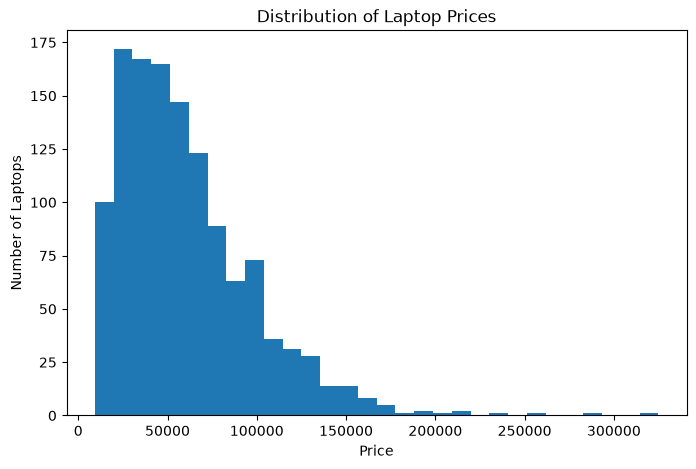

In [176]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df_clean['Price'], bins=30)
plt.xlabel('Price')
plt.ylabel('Number of Laptops')
plt.title('Distribution of Laptop Prices')
plt.show()

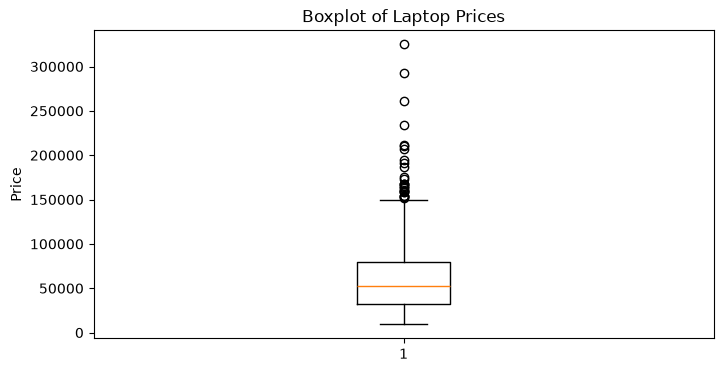

In [177]:
plt.figure(figsize=(8, 4))
plt.boxplot(df_clean['Price'])
plt.ylabel('Price')
plt.title('Boxplot of Laptop Prices')
plt.show()

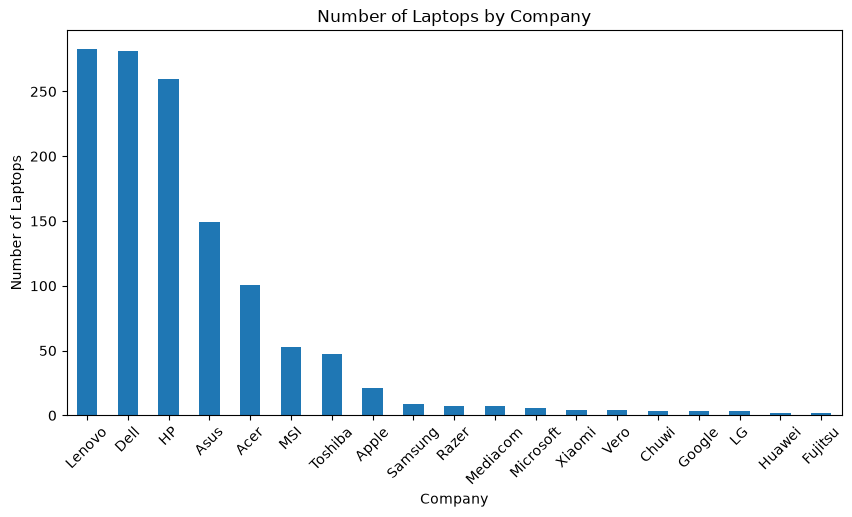

In [178]:
plt.figure(figsize=(10, 5))

df_clean['Company'].value_counts().plot(kind='bar')

plt.xlabel('Company')
plt.ylabel('Number of Laptops')
plt.title('Number of Laptops by Company')
plt.xticks(rotation=45)
plt.show()

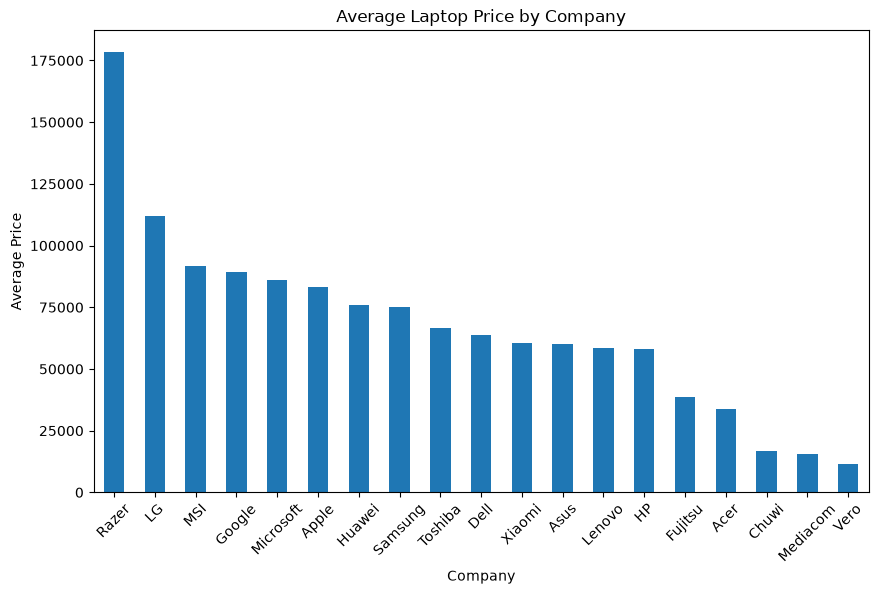

In [179]:
company_avg_price = df_clean.groupby('Company')['Price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
company_avg_price.plot(kind='bar')

plt.xlabel('Company')
plt.ylabel('Average Price')
plt.title('Average Laptop Price by Company')
plt.xticks(rotation=45)
plt.show()

# 11. Bivariate Analysis


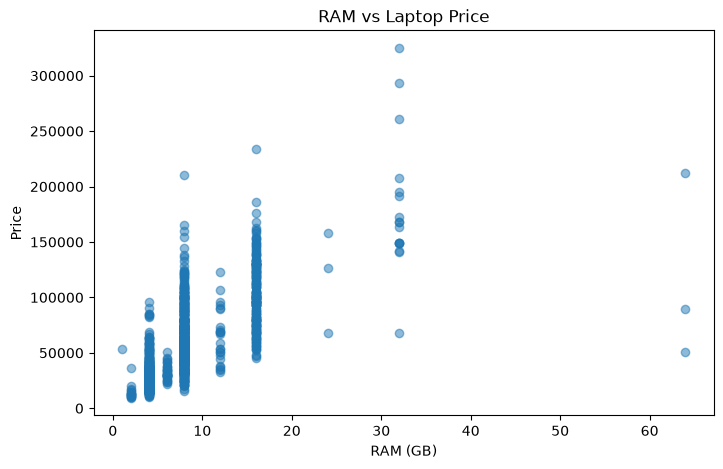

In [180]:
plt.figure(figsize=(8, 5))

plt.scatter(df_clean['Ram'], df_clean['Price'], alpha=0.5)

plt.xlabel('RAM (GB)')
plt.ylabel('Price')
plt.title('RAM vs Laptop Price')

plt.show()

In [181]:
df_clean['Ram'].corr(df_clean['Price'])

np.float64(0.6795406117947836)

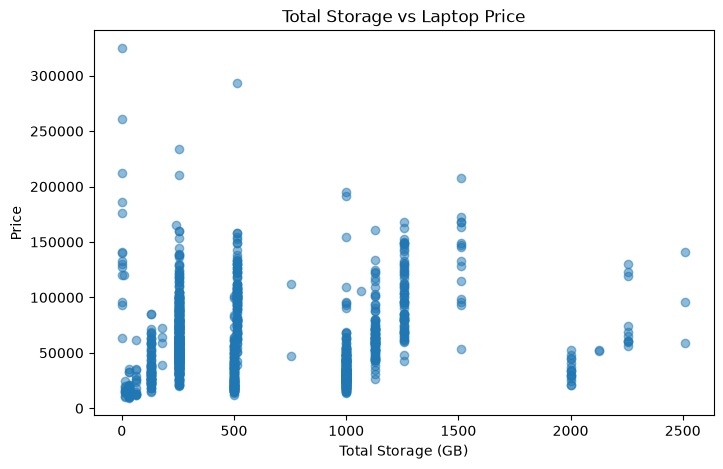

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
df_clean['Total_Storage_GB'],
df_clean['Price'],
alpha=0.5
)

plt.xlabel('Total Storage (GB)')
plt.ylabel('Price')
plt.title('Total Storage vs Laptop Price')

plt.show()

In [183]:
df_clean['Total_Storage_GB'].corr(df_clean['Price'])

np.float64(0.08642909194066088)

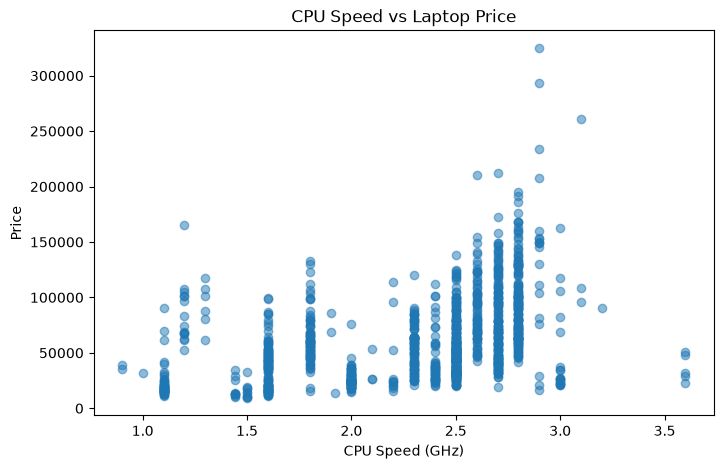

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
df_clean['CPU_Speed_GHz'],
df_clean['Price'],
 alpha=0.5
)

plt.xlabel('CPU Speed (GHz)')
plt.ylabel('Price')
plt.title('CPU Speed vs Laptop Price')

plt.show()

In [185]:
df_clean['CPU_Speed_GHz'].corr(df_clean['Price'])

np.float64(0.4275971872968001)

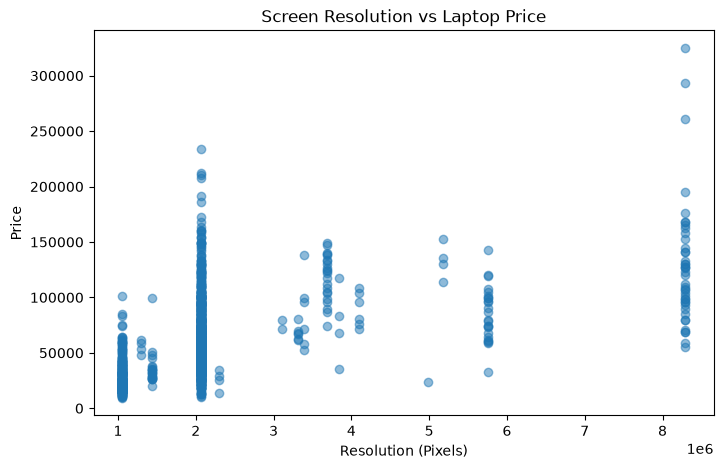

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
df_clean['Resolution_Pixels'],
df_clean['Price'],
alpha=0.5
)

plt.xlabel('Resolution (Pixels)')
plt.ylabel('Price')
plt.title('Screen Resolution vs Laptop Price')

plt.show()

In [187]:
df_clean['Resolution_Pixels'].corr(df_clean['Price'])

np.float64(0.5129811658976433)

<Figure size 1000x600 with 0 Axes>

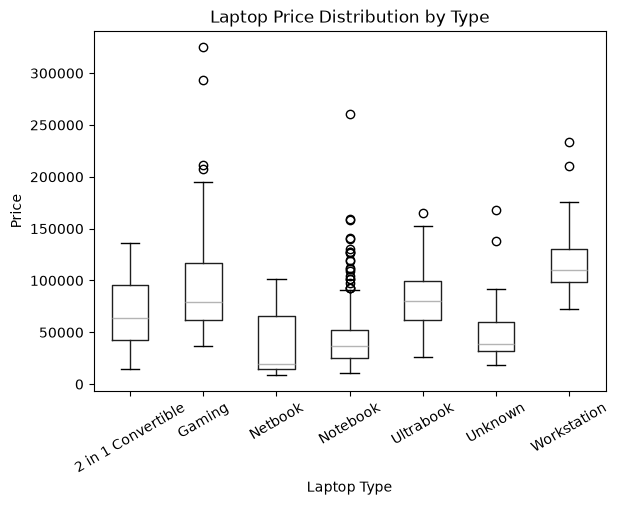

In [ ]:
plt.figure(figsize=(10, 6))

df_clean.boxplot(
column='Price',
by='TypeName',
grid=False
)

plt.xlabel('Laptop Type')
plt.ylabel('Price')
plt.title('Laptop Price Distribution by Type')
plt.suptitle('')

plt.xticks(rotation=30)
plt.show()

<Figure size 800x500 with 0 Axes>

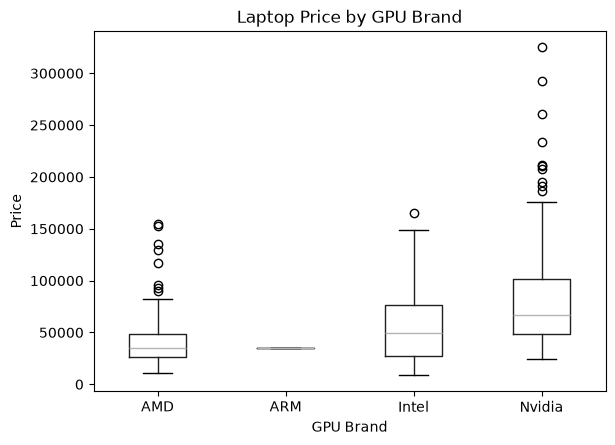

In [ ]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
column='Price',
by='GPU_Brand',
grid=False
)

plt.xlabel('GPU Brand')
plt.ylabel('Price')
plt.title('Laptop Price by GPU Brand')
plt.suptitle('')

plt.show()

In [190]:
ram_avg_price = df_clean.groupby('Ram')['Price'].mean().sort_index()

print(ram_avg_price)

Ram
1.0      53226.720000
2.0      14693.527059
4.0      30798.110060
6.0      33016.614982
8.0      63024.097754
12.0     64664.071200
16.0    103400.887275
24.0    117553.440000
32.0    181849.215812
64.0    117511.526400
Name: Price, dtype: float64


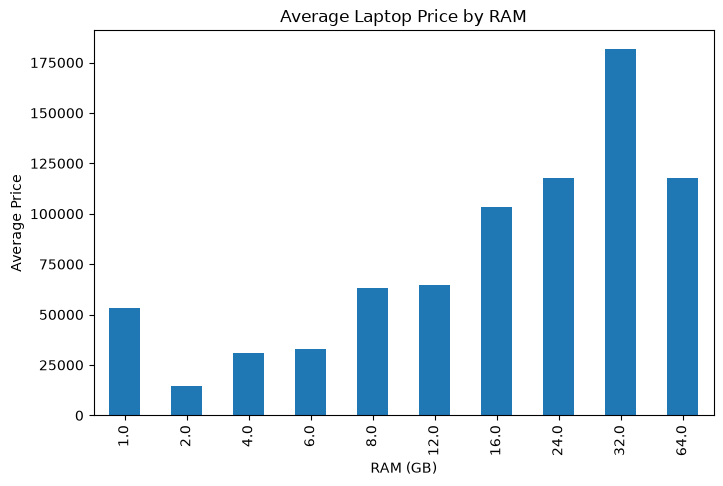

In [191]:
plt.figure(figsize=(8, 5))

ram_avg_price.plot(kind='bar')

plt.xlabel('RAM (GB)')
plt.ylabel('Average Price')
plt.title('Average Laptop Price by RAM')

plt.show()

Text(0.5, 1.0, 'Correlation Heatmap of Numerical Features')

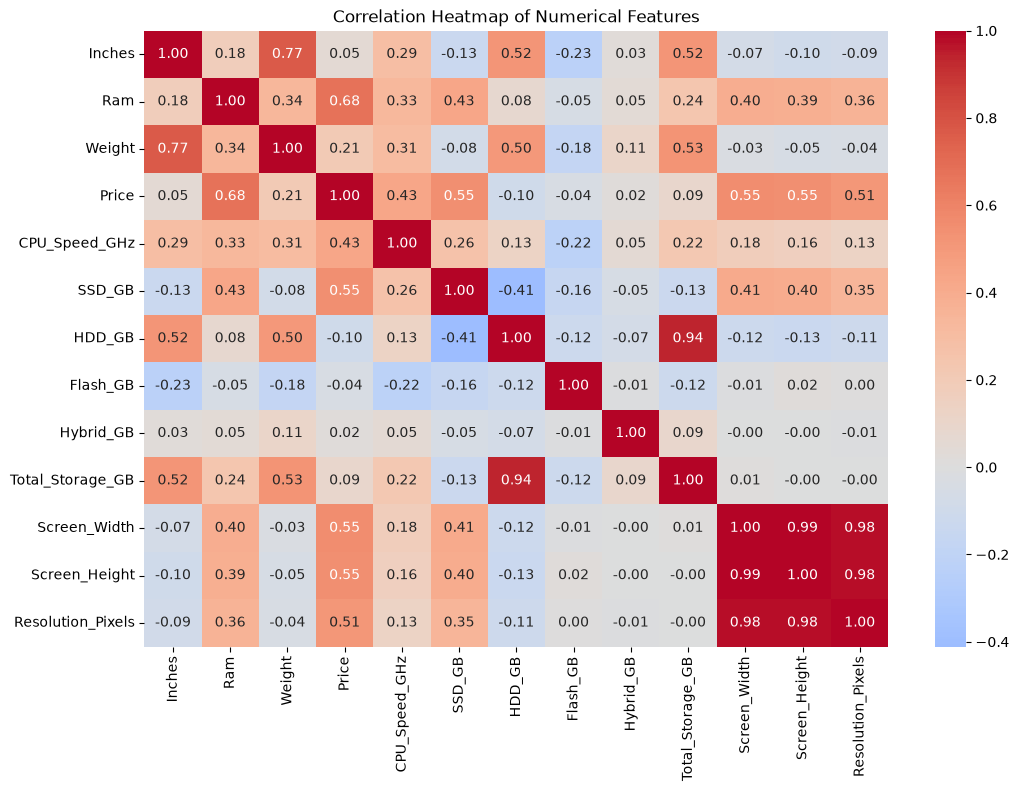

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [
'Inches',
'Ram',
'Weight',
'Price',
'CPU_Speed_GHz',
'SSD_GB',
'HDD_GB',
'Flash_GB',
'Hybrid_GB',
'Total_Storage_GB',
'Screen_Width',
'Screen_Height',
'Resolution_Pixels'
]

correlation = df_clean[numeric_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
correlation,
annot=True,
fmt='.2f',
cmap='coolwarm',
center=0
)

plt.title('Correlation Heatmap of Numerical Features')


In [193]:
price_correlation = correlation['Price'].sort_values(ascending=False)

print(price_correlation)

Price                1.000000
Ram                  0.679541
Screen_Width         0.553533
SSD_GB               0.551968
Screen_Height        0.549803
Resolution_Pixels    0.512981
CPU_Speed_GHz        0.427597
Weight               0.211395
Total_Storage_GB     0.086429
Inches               0.054301
Hybrid_GB            0.022582
Flash_GB            -0.036874
HDD_GB              -0.095271
Name: Price, dtype: float64


In [ ]:
company_price = (
df_clean.groupby('Company')['Price']
.agg(['count', 'mean', 'median'])
.sort_values('mean', ascending=False)
)

print(company_price)

           count           mean       median
Company                                     
Razer          7  178282.491429  154458.7200
LG             3  111834.720000  111834.7200
MSI           53   91814.548891   85194.7200
Google         3   89386.080000   83063.5200
Microsoft      6   85903.788000   83622.9600
Apple         21   83340.499886   71378.6832
Huawei         2   75870.720000   75870.7200
Samsung        9   75308.320000   87858.7200
Toshiba       47   66747.370213   64468.8000
Dell         281   63963.889520   53226.7200
Xiaomi         4   60390.882000   58578.6960
Asus         149   60310.535581   55938.6720
Lenovo       283   58322.618765   47898.7200
HP           260   57910.511520   52161.1200
Fujitsu        2   38574.720000   38574.7200
Acer         101   33750.986186   30476.1600
Chuwi          3   16745.726400   13261.3920
Mediacom       7   15717.600000   14119.2000
Vero           4   11584.404000   11020.9680


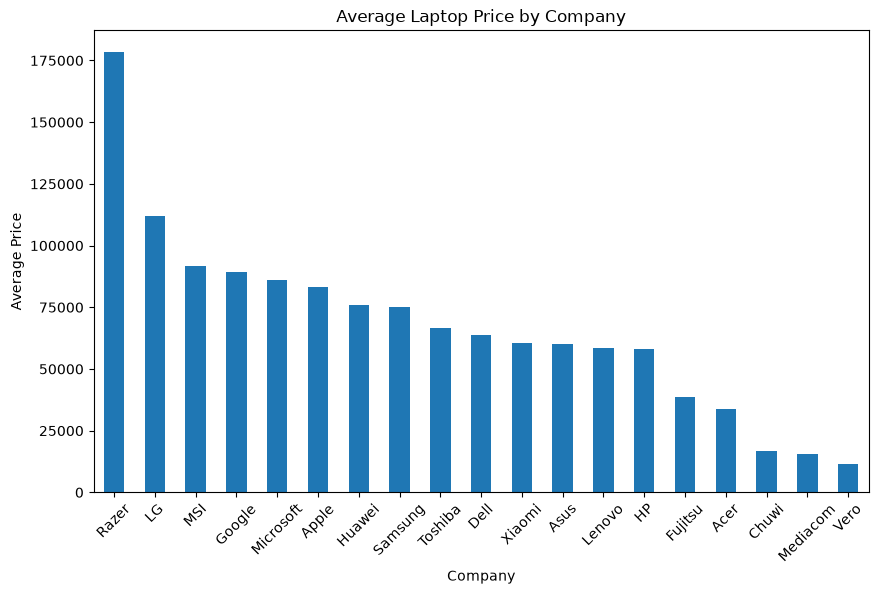

In [195]:
plt.figure(figsize=(10, 6))

company_price['mean'].plot(kind='bar')

plt.xlabel('Company')
plt.ylabel('Average Price')
plt.title('Average Laptop Price by Company')
plt.xticks(rotation=45)
plt.show()

In [ ]:
type_price = (
df_clean.groupby('TypeName')['Price']
.agg(['count', 'mean', 'median'])
.sort_values('mean', ascending=False)
)

print(type_price)

                    count           mean       median
TypeName                                             
Workstation            29  121497.525683  110017.8720
Gaming                202   91830.627945   79008.1128
Ultrabook             189   83392.545143   79920.0000
2 in 1 Convertible    110   68266.990735   63882.7200
Unknown                20   53583.376320   39000.6936
Notebook              673   41866.175522   37189.4400
Netbook                22   37043.888727   19713.6000


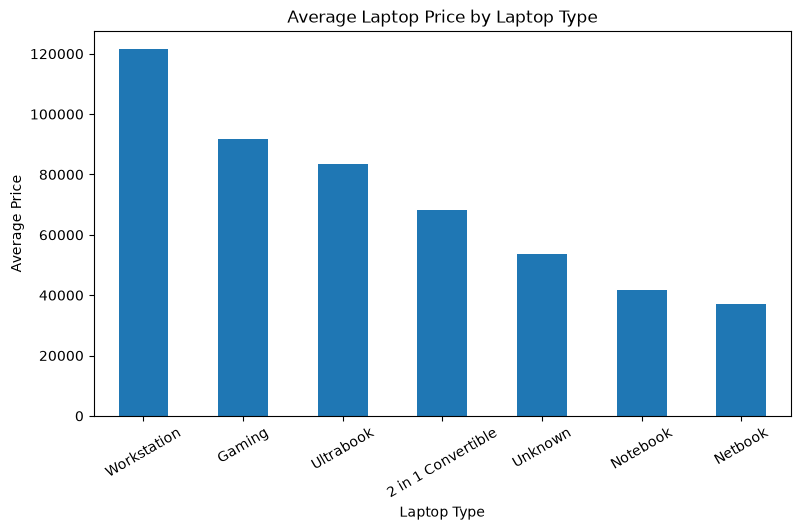

In [197]:
plt.figure(figsize=(9, 5))

type_price['mean'].plot(kind='bar')

plt.xlabel('Laptop Type')
plt.ylabel('Average Price')
plt.title('Average Laptop Price by Laptop Type')
plt.xticks(rotation=30)
plt.show()

In [ ]:
gpu_price = (
df_clean.groupby('GPU_Brand')['Price']
.agg(['count', 'mean', 'median'])
.sort_values('mean', ascending=False)
)

print(gpu_price)

           count          mean    median
GPU_Brand                               
Nvidia       389  79620.267813  66546.72
Intel        685  54492.526795  49443.84
AMD          170  41597.457374  35218.08
ARM            1  35111.520000  35111.52


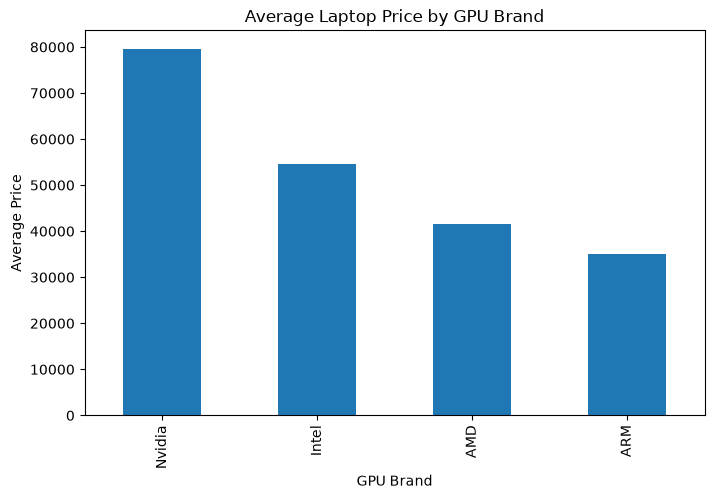

In [199]:
plt.figure(figsize=(8, 5))

gpu_price['mean'].plot(kind='bar')

plt.xlabel('GPU Brand')
plt.ylabel('Average Price')
plt.title('Average Laptop Price by GPU Brand')
plt.show()

In [ ]:
cpu_price = (
df_clean.groupby('CPU_Family')['Price']
.agg(['count', 'mean', 'median'])
.sort_values('mean', ascending=False)
)

print(cpu_price)

                count           mean       median
CPU_Family                                       
Intel Xeon          4  190955.520000  198308.1600
AMD Ryzen           4   89803.440000   86420.1600
Intel Core i7     503   86050.541917   79014.2400
Intel Core M       17   74286.110118   68145.1200
Intel Core i5     410   54230.522997   51095.5200
AMD FX              2   45234.720000   45234.7200
Samsung Cortex      1   35111.520000   35111.5200
AMD A12-Series      8   34902.196200   32675.8248
AMD A10-Series      6   30599.680800   30476.1600
Intel Core i3     132   28995.270655   26586.7200
AMD A9-Series      15   25570.421760   24988.3200
AMD A8-Series       4   23896.080000   24455.5200
Intel Pentium      30   23205.571200   21111.6672
AMD A6-Series      11   21570.068945   21258.7200
AMD A4-Series       1   20193.120000   20193.1200
Intel Atom         11   17354.555345   13266.7200
Intel Celeron      77   17127.035906   16221.0960
AMD E-Series        9   16031.300800   15930.7200


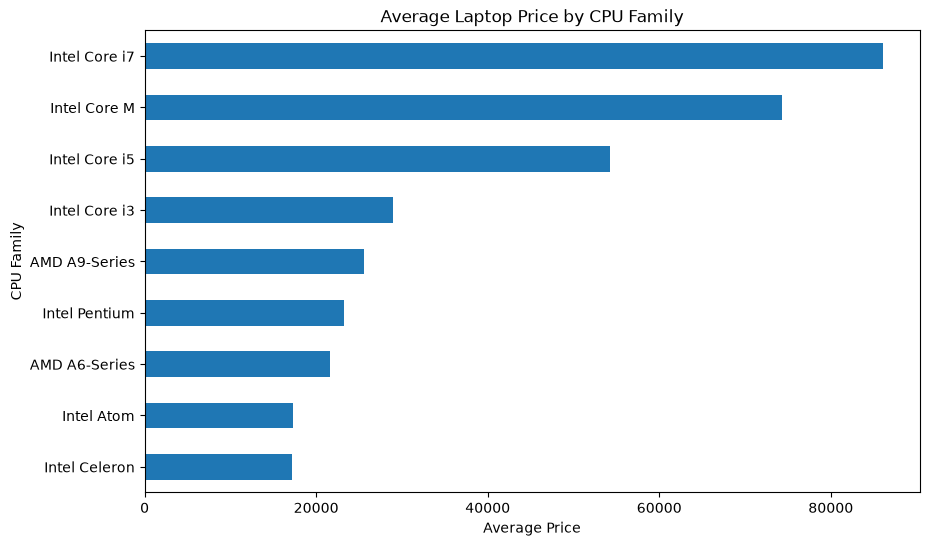

In [201]:
cpu_price_filtered = cpu_price[cpu_price['count'] >= 10]

plt.figure(figsize=(10, 6))

cpu_price_filtered['mean'].sort_values().plot(kind='barh')

plt.xlabel('Average Price')
plt.ylabel('CPU Family')
plt.title('Average Laptop Price by CPU Family')

plt.show()

In [ ]:
print(
df_clean.groupby('Touchscreen')['Price']
.agg(['count', 'mean', 'median'])
)

             count          mean    median
Touchscreen                               
False         1064  57686.138323  50296.32
True           181  77504.381940  74538.72


In [ ]:
print(
df_clean.groupby('IPS_Panel')['Price']
.agg(['count', 'mean', 'median'])
)

           count          mean     median
IPS_Panel                                
False        894  54625.970207  46193.760
True         351  75700.076759  67260.672


In [ ]:
print(
df_clean.groupby('Retina_Display')['Price']
.agg(['count', 'mean', 'median'])
)

                count          mean    median
Retina_Display                               
False            1228  60183.001489  52161.12
True               17  88330.498729  80452.80


In [ ]:
price_corr = (
df_clean.select_dtypes(include='number')
.corr()['Price']
.sort_values(ascending=False)
)

print(price_corr)

Price                1.000000
Ram                  0.679541
Screen_Width         0.553533
SSD_GB               0.551968
Screen_Height        0.549803
Resolution_Pixels    0.512981
CPU_Speed_GHz        0.427597
Weight               0.211395
Total_Storage_GB     0.086429
Inches               0.054301
Hybrid_GB            0.022582
Flash_GB            -0.036874
HDD_GB              -0.095271
Name: Price, dtype: float64


In [207]:
print("Top positive correlations with Price:")
print(price_corr.drop('Price').sort_values(ascending=False).head(10))

Top positive correlations with Price:
Ram                  0.679541
Screen_Width         0.553533
SSD_GB               0.551968
Screen_Height        0.549803
Resolution_Pixels    0.512981
CPU_Speed_GHz        0.427597
Weight               0.211395
Total_Storage_GB     0.086429
Inches               0.054301
Hybrid_GB            0.022582
Name: Price, dtype: float64


In [ ]:
top_10_laptops = df_clean.sort_values(
'Price',
ascending=False
).head(10)

top_10_laptops[
[
'Company',
'TypeName',
'Inches',
'Ram',
'CPU_Family',
'GPU_Brand',
'Total_Storage_GB',
'Price'
]
]

,Company,TypeName,Inches,Ram,CPU_Family,GPU_Brand,Total_Storage_GB,Price
196,Razer,Gaming,17.3,32.0,Intel Core i7,Nvidia,0.0,324954.720
830,Razer,Gaming,17.3,32.0,Intel Core i7,Nvidia,512.0,292986.720
610,Lenovo,Notebook,15.6,32.0,Intel Xeon,Nvidia,0.0,261018.720
749,HP,Workstation,17.3,16.0,Intel Xeon,Nvidia,256.0,233845.920
1066,Asus,Gaming,17.3,64.0,Intel Core i7,Nvidia,0.0,211788.000
1136,HP,Workstation,17.3,8.0,Intel Core i7,Nvidia,256.0,210424.032
238,Asus,Gaming,17.3,32.0,Intel Core i7,Nvidia,1512.0,207259.200
723,Dell,Gaming,17.3,32.0,Intel Core i7,Nvidia,1000.0,194972.832
780,Dell,Gaming,17.3,32.0,Intel Core i7,Nvidia,1000.0,191211.264
1231,Razer,Gaming,14.0,16.0,Intel Core i7,Nvidia,0.0,186426.720


In [ ]:
df_clean['RAM_per_1000_AED'] = (
df_clean['Ram'] / (df_clean['Price'] / 1000)
)

In [ ]:
best_value = df_clean.sort_values(
'RAM_per_1000_AED',
ascending=False
).head(10)

best_value[
[
'Company',
'TypeName',
'Ram',
'CPU_Family',
'GPU_Brand',
'Price',
'RAM_per_1000_AED'
]
]

,Company,TypeName,Ram,CPU_Family,GPU_Brand,Price,RAM_per_1000_AED
71,Dell,Ultrabook,64.0,Intel Core i7,AMD,50882.4000,1.257802
720,Lenovo,Ultrabook,64.0,Intel Core i7,Intel,89864.1792,0.712186
378,Asus,Notebook,8.0,Intel Celeron,Intel,15238.0800,0.525001
901,Asus,Gaming,32.0,Intel Core i7,Nvidia,68145.1200,0.469586
783,Lenovo,Notebook,8.0,Intel Celeron,Intel,17529.1200,0.456383
348,Asus,2 in 1 Convertible,8.0,Intel Celeron,Intel,19980.0000,0.400400
571,HP,Notebook,8.0,Intel Pentium,Intel,20725.9200,0.385990
74,Acer,Notebook,8.0,Intel Core i3,Intel,20725.9200,0.385990
365,HP,Notebook,8.0,Intel Pentium,Intel,20725.9200,0.385990
1120,Vero,Notebook,4.0,Intel Atom,Intel,10442.8800,0.383036


In [223]:
df_clean.to_csv(
'laptop_cleaned_final.csv',
index=False
)

In [213]:
company_avg = df_clean.groupby('Company')['Price'].mean().sort_values(ascending=False)

print("Highest average price:")
print(company_avg.head(5))

Highest average price:
Company
Razer        178282.491429
LG           111834.720000
MSI           91814.548891
Google        89386.080000
Microsoft     85903.788000
Name: Price, dtype: float64


In [214]:
type_avg = df_clean.groupby('TypeName')['Price'].mean().sort_values(ascending=False)

print("Average price by laptop type:")
print(type_avg)

Average price by laptop type:
TypeName
Workstation           121497.525683
Gaming                 91830.627945
Ultrabook              83392.545143
2 in 1 Convertible     68266.990735
Unknown                53583.376320
Notebook               41866.175522
Netbook                37043.888727
Name: Price, dtype: float64


In [215]:
gpu_avg = df_clean.groupby('GPU_Brand')['Price'].mean().sort_values(ascending=False)

print("Average price by GPU brand:")
print(gpu_avg)

Average price by GPU brand:
GPU_Brand
Nvidia    79620.267813
Intel     54492.526795
AMD       41597.457374
ARM       35111.520000
Name: Price, dtype: float64


In [216]:
print("Touchscreen:")
print(df_clean.groupby('Touchscreen')['Price'].mean())

print("\nIPS Panel:")
print(df_clean.groupby('IPS_Panel')['Price'].mean())

print("\nRetina Display:")
print(df_clean.groupby('Retina_Display')['Price'].mean())

Touchscreen:
Touchscreen
False    57686.138323
True     77504.381940
Name: Price, dtype: float64

IPS Panel:
IPS_Panel
False    54625.970207
True     75700.076759
Name: Price, dtype: float64

Retina Display:
Retina_Display
False    60183.001489
True     88330.498729
Name: Price, dtype: float64


In [ ]:
corr_price = (
df_clean.select_dtypes(include='number')
.corr()['Price']
.drop('Price')
.sort_values(ascending=False)
)

print(corr_price)

Ram                  0.679541
Screen_Width         0.553533
SSD_GB               0.551968
Screen_Height        0.549803
Resolution_Pixels    0.512981
CPU_Speed_GHz        0.427597
Weight               0.211395
Total_Storage_GB     0.086429
Inches               0.054301
Hybrid_GB            0.022582
Flash_GB            -0.036874
HDD_GB              -0.095271
RAM_per_1000_AED    -0.397567
Name: Price, dtype: float64


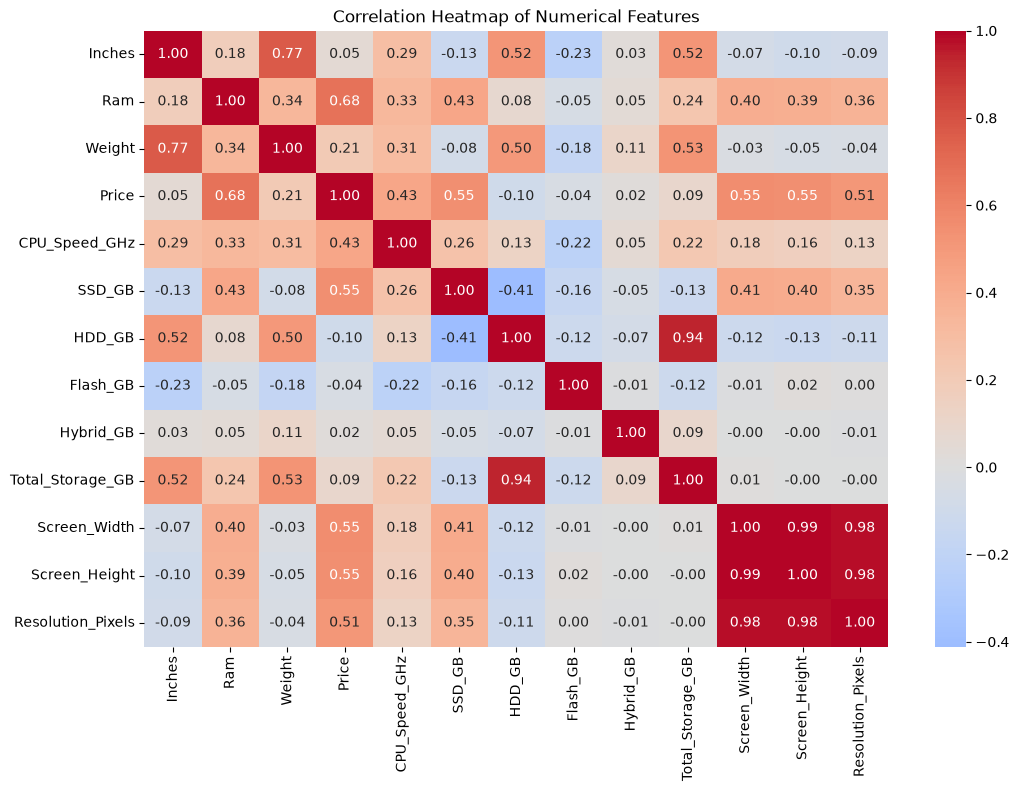

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [
'Inches',
'Ram',
'Weight',
'Price',
'CPU_Speed_GHz',
'SSD_GB',
'HDD_GB',
'Flash_GB',
'Hybrid_GB',
'Total_Storage_GB',
'Screen_Width',
'Screen_Height',
'Resolution_Pixels'
]

corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
corr_matrix,
annot=True,
fmt='.2f',
cmap='coolwarm',
center=0
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [219]:
price_corr = corr_matrix['Price'].sort_values(ascending=False)

print(price_corr)

Price                1.000000
Ram                  0.679541
Screen_Width         0.553533
SSD_GB               0.551968
Screen_Height        0.549803
Resolution_Pixels    0.512981
CPU_Speed_GHz        0.427597
Weight               0.211395
Total_Storage_GB     0.086429
Inches               0.054301
Hybrid_GB            0.022582
Flash_GB            -0.036874
HDD_GB              -0.095271
Name: Price, dtype: float64


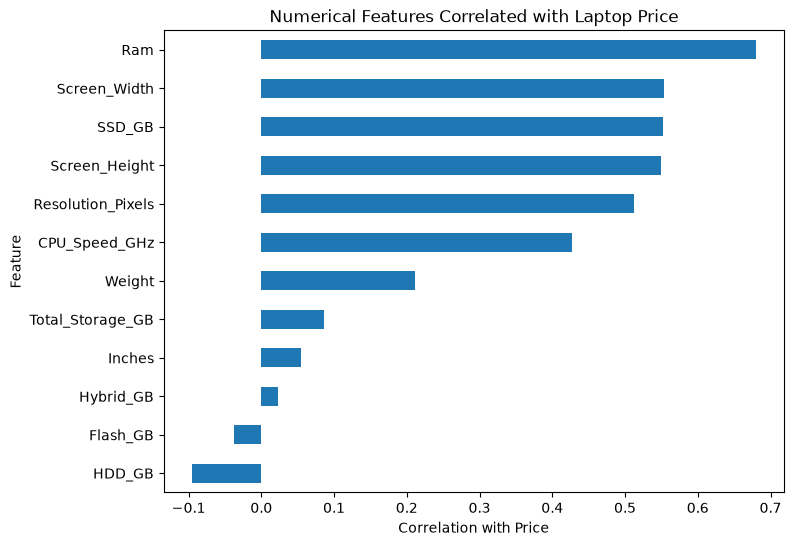

In [220]:
price_corr_without_price = price_corr.drop('Price').sort_values()

plt.figure(figsize=(8, 6))

price_corr_without_price.plot(kind='barh')

plt.xlabel('Correlation with Price')
plt.ylabel('Feature')
plt.title('Numerical Features Correlated with Laptop Price')

plt.show()

In [ ]:
# 11. Multivariate Analysis

In [ ]:
multi_cols = [
'Ram',
'CPU_Speed_GHz',
'Total_Storage_GB',
'Resolution_Pixels',
'Weight',
'Price'
]

df_clean[multi_cols].corr()

,Ram,CPU_Speed_GHz,Total_Storage_GB,Resolution_Pixels,Weight,Price
Ram,1.000000,0.329667,0.241040,0.360926,0.338629,0.679541
CPU_Speed_GHz,0.329667,1.000000,0.224617,0.126590,0.306085,0.427597
Total_Storage_GB,0.241040,0.224617,1.000000,-0.001922,0.528751,0.086429
Resolution_Pixels,0.360926,0.126590,-0.001922,1.000000,-0.041135,0.512981
Weight,0.338629,0.306085,0.528751,-0.041135,1.000000,0.211395
Price,0.679541,0.427597,0.086429,0.512981,0.211395,1.000000


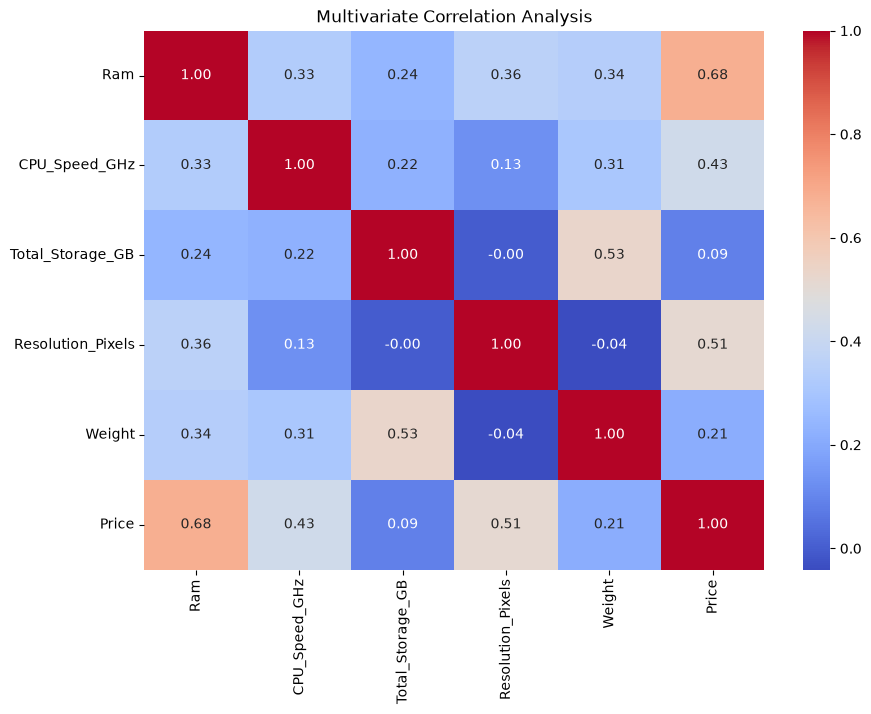

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

sns.heatmap(
df_clean[multi_cols].corr(),
annot=True,
cmap='coolwarm',
fmt='.2f'
)

plt.title('Multivariate Correlation Analysis')
plt.show()

In [221]:
print("Shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

Shape: (1245, 26)

Missing values:
0

Duplicate rows:
0

Data types:
Company                  str
TypeName                 str
Inches               float64
ScreenResolution         str
Cpu                      str
Ram                  float64
Memory                   str
Gpu                      str
OpSys                    str
Weight               float64
Price                float64
CPU_Speed_GHz        float64
CPU_Family               str
GPU_Brand                str
SSD_GB               float64
HDD_GB               float64
Flash_GB             float64
Hybrid_GB            float64
Total_Storage_GB     float64
Screen_Width           int64
Screen_Height          int64
Resolution_Pixels      int64
Touchscreen             bool
IPS_Panel               bool
Retina_Display          bool
RAM_per_1000_AED     float64
dtype: object


In [222]:
df_clean.to_csv('laptop_cleaned_final.csv', index=False)

## Key EDA Insights
The exploratory data analysis of the laptop dataset provided several important insights into the factors influencing laptop prices. After data cleaning, duplicate removal, missing-value treatment, inconsistent value handling, and feature engineering, the final dataset contained 1,245 laptop records and 25 features, with no remaining missing values or duplicate records.
The analysis showed that RAM is one of the strongest hardware-related factors associated with laptop price. The correlation between RAM and Price was approximately 0.68, indicating a relatively strong positive relationship. Higher-RAM laptops generally tend to be more expensive because they are designed for more demanding applications and workloads. Screen resolution was also positively related to price, with Resolution_Pixels showing a correlation of approximately 0.51 with Price.
Storage configuration was another important factor. SSD capacity showed a positive correlation of approximately 0.52 with price, suggesting that laptops with larger SSD capacities generally command higher prices. CPU speed also showed a positive relationship with price, although weaker than RAM and storage. The correlation between CPU speed and Price was approximately 0.43.
The analysis of laptop brands showed that Lenovo, Dell, and HP were the most frequently represented companies in the dataset. However, frequency did not necessarily correspond to higher average prices. Premium brands and specialized laptop categories, particularly Razer, Apple, gaming laptops, and workstations, were generally associated with higher prices.
The laptop-type analysis showed that Notebook was the most common category, followed by Gaming and Ultrabook laptops. Gaming and workstation laptops frequently appeared among the higher-priced products because they generally combine powerful CPUs, higher RAM, dedicated GPUs, and larger storage capacities.
GPU analysis showed that Intel GPUs were the most common, followed by Nvidia and AMD. Nvidia GPUs were particularly common among gaming and high-performance laptops. This indicates that GPU configuration is an important characteristic when examining premium laptop pricing.
The analysis also identified several unusual values in the original dataset. For example, some screen-size and weight values were clearly inconsistent with realistic laptop specifications. These were identified during data-quality analysis and handled before the final analysis. Price and weight outliers were also examined rather than being automatically removed, because some high-priced or heavy gaming/workstation laptops may represent genuine products rather than data-entry errors.
Overall, the analysis indicates that laptop price is determined by a combination of specifications rather than a single feature. RAM, storage, processor characteristics, display resolution, GPU type, laptop category, and brand all contribute to the overall pricing pattern. These findings can help customers compare laptops based on specifications and can also help businesses understand which product characteristics are associated with higher market prices.

# 16. Conclusion
The objective of this project was to perform an exploratory data analysis of laptop specifications and understand the major factors associated with laptop prices. The dataset was systematically cleaned by handling missing values, removing duplicate records, correcting inconsistent values, treating unrealistic observations, and creating meaningful derived features.
The analysis demonstrated that RAM, SSD capacity, screen resolution, and CPU speed have positive relationships with laptop price, with RAM showing one of the strongest relationships. Gaming and workstation laptops were generally positioned toward the higher-priced segment because of their powerful processors, higher RAM, dedicated GPUs, and advanced hardware configurations.
The project also demonstrated the importance of data cleaning before performing statistical and exploratory analysis. By transforming raw specifications into structured variables such as CPU family, CPU speed, GPU brand, storage components, screen dimensions, and resolution, the dataset became more suitable for analysis.
Overall, the findings suggest that laptop pricing depends on a combination of performance, storage, display, GPU, product category, and brand characteristics. The analysis provides a useful foundation for further work such as machine-learning-based laptop price prediction, feature-importance analysis, and development of an interactive Power BI dashboard.

# Laptop Price Analysis — Exploratory Data Analysis

## Objective

The objective of this project is to perform exploratory data analysis
on a laptop dataset to understand the factors associated with laptop
prices and identify patterns across brands, laptop types, hardware
specifications, storage, display characteristics, and other features.

## Dataset Overview

The dataset contains information about laptops including company,
laptop type, screen size, processor, RAM, storage, GPU, operating
system, weight, and price.

After data cleaning and feature engineering, the final dataset contains
1,245 records and 25 features.

## Executive Summary

This project analyzed a laptop dataset to identify the major factors
associated with laptop prices.

After data cleaning, missing-value handling, duplicate removal, data
type conversion, and feature engineering, the final dataset contained
1,245 records and 25 features with no remaining missing values or
duplicate rows.

The analysis showed that RAM, SSD capacity, CPU speed, and screen
resolution have positive relationships with laptop price. RAM showed
one of the strongest relationships with price. Laptop type and GPU
configuration also contributed to differences in pricing.

The analysis further showed that screen size alone has a very weak
linear relationship with price. Premium gaming and workstation laptops
generally occupy the higher end of the price range because they tend
to combine powerful processors, higher RAM, dedicated GPUs, and larger
storage capacities.

Overall, laptop price is influenced by a combination of hardware
performance, storage, display characteristics, and product category
rather than a single specification.

## Limitations

- Correlation does not imply causation.
- The analysis identifies relationships in the available dataset but
does not establish that a particular specification directly causes a change in price.
- Some laptop brands and configurations have relatively few observations.
- The dataset represents a specific collection of laptop listings and
may not represent the entire laptop market.
- Price can also be influenced by factors such as model generation,
release year, brand positioning, and market conditions that are not  included in the dataset.

## Future Scope

Future analysis could include:

- Building a machine-learning model to predict laptop prices.
- Comparing different regression algorithms.
- Performing feature importance analysis.
- Applying categorical encoding to company, CPU, GPU, and operating system features.
- Comparing predicted prices with actual prices.
- Developing an interactive Power BI dashboard for laptop price
analysis.